# Exploratory Data Analysis

- **Goal**: Understand trend, seasonality and demand drivers to decide how to model demand.
- **Input**: `data/inventory_demand_forecasting.csv`
- **Output**: Key insights ([Section 5](#section-5)) and figures in `outputs/figures/`; data checks in Section 0.1

## 0. Setup and Data Overview

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "utils.py").exists())
sys.path.insert(0, str(ROOT))   # lets `from src.utils import ...` work from notebooks/ or the project root
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.utils import (
    load_data,
    add_calendar_features,
    MONTH_ORDER,
    DAY_ORDER,
    save_figure,
    set_plot_style,
)

set_plot_style()
data = add_calendar_features(load_data())
data.head(5)

,date,product_id,category,price,promotion,stock,demand,year,month,month_name,day_of_week,day_name,day_of_year
0,2023-01-01,A,Electronics,116,1,121,95,2023,1,Jan,6,Sunday,1
1,2023-01-02,A,Electronics,199,0,495,85,2023,1,Jan,0,Monday,2
2,2023-01-03,A,Electronics,17,0,480,76,2023,1,Jan,1,Tuesday,3
3,2023-01-04,A,Electronics,197,0,429,80,2023,1,Jan,2,Wednesday,4
4,2023-01-05,A,Electronics,160,0,111,66,2023,1,Jan,3,Thursday,5


In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         3650 non-null   datetime64[us]
 1   product_id   3650 non-null   str           
 2   category     3650 non-null   str           
 3   price        3650 non-null   int64         
 4   promotion    3650 non-null   int64         
 5   stock        3650 non-null   int64         
 6   demand       3650 non-null   int64         
 7   year         3650 non-null   int32         
 8   month        3650 non-null   int32         
 9   month_name   3650 non-null   str           
 10  day_of_week  3650 non-null   int32         
 11  day_name     3650 non-null   str           
 12  day_of_year  3650 non-null   int32         
dtypes: datetime64[us](1), int32(4), int64(4), str(4)
memory usage: 313.8 KB


In [3]:
# Validation of unique identifiers and flags
print("Products:", data['product_id'].unique().tolist())
print("Categories:", data['category'].unique().tolist())
print("Promotion values:", data['promotion'].unique().tolist())

Products: ['A', 'B', 'C', 'D', 'E']
Categories: ['Electronics', 'Grocery', 'Clothing', 'Home', 'Sports']
Promotion values: [1, 0]


### 0.1 What kind of data is this?

The conclusions of an EDA hold only for the data that produced them. Before modelling, we test what generated the columns, so that later findings are read in the right light.

In [4]:
from scipy import stats
pd.set_option('display.max_colwidth', None)

span = pd.date_range(data['date'].min(), data['date'].max(), freq='D')
checks = []
def add(check, result, reading):
    checks.append({'check': check, 'result': result, 'reading': reading})

add('Calendar', f"{span[0].date()} to {span[-1].date()}, {len(span) - data['date'].nunique()} missing days", 'complete daily series, no gaps to impute')
one_to_one = data.groupby('product_id')['category'].nunique().max() == 1 and data.groupby('category')['product_id'].nunique().max() == 1
add('category vs product_id', f"one-to-one: {one_to_one}", 'category adds nothing beyond product_id')
for col in ('price', 'stock'):
    counts = np.histogram(data[col], bins=10)[0]
    add(f'{col} distribution', f"range {data[col].min():.0f}-{data[col].max():.0f}; ten equal-width bins hold {counts.min() / len(data):.1%}-{counts.max() / len(data):.1%} each (chi-square p = {stats.chisquare(counts).pvalue:.2f})",
        'indistinguishable from a uniform random draw')
    add(f'{col} vs demand', f"Spearman rho = {stats.spearmanr(data[col], data['demand'])[0]:+.3f}", 'no relationship')
low_stock = data['stock'] <= data['stock'].quantile(0.10)
add('stock as a cap on demand', f"demand exceeds stock on {(data['demand'] > data['stock']).mean():.1%} of rows; mean demand when stock is in its lowest decile {data.loc[low_stock, 'demand'].mean():.1f} vs {data['demand'].mean():.1f} overall",
    'stock does not limit demand, so demand is not censored')
promo = data.pivot(index='date', columns='product_id', values='promotion')
off = promo.corr().to_numpy()[np.triu_indices(promo.shape[1], 1)]
add('promotion across products', f"promotion on {data['promotion'].mean():.1%} of days; pairwise correlation between products {off.min():+.2f} to {off.max():+.2f}",
    'promotion days are scheduled independently for each product')
pd.DataFrame(checks).set_index('check')

,result,reading
check,,
Calendar,"2023-01-01 to 2024-12-30, 0 missing days","complete daily series, no gaps to impute"
category vs product_id,one-to-one: True,category adds nothing beyond product_id
price distribution,range 10-199; ten equal-width bins hold 8.7%-10.8% each (chi-square p = 0.17),indistinguishable from a uniform random draw
price vs demand,Spearman rho = -0.020,no relationship
stock distribution,range 50-499; ten equal-width bins hold 9.2%-10.7% each (chi-square p = 0.70),indistinguishable from a uniform random draw
stock vs demand,Spearman rho = -0.015,no relationship
stock as a cap on demand,demand exceeds stock on 6.6% of rows; mean demand when stock is in its lowest decile 72.7 vs 71.7 overall,"stock does not limit demand, so demand is not censored"
promotion across products,promotion on 19.9% of days; pairwise correlation between products -0.12 to +0.06,promotion days are scheduled independently for each product


**Observations**:
- The calendar is complete (730 days, no gaps), so the rolling-window code, which works by position, is safe.
- `category` maps one-to-one to `product_id`, so it carries no information beyond the product itself (and Electronics and Grocery turn out to have the same demand pattern).
- `price` (10-199) and `stock` (50-499) are indistinguishable from independent uniform random draws and are unrelated to demand. `stock` does not cap demand: demand exceeds it on 6.6% of rows and is no lower when stock is lowest, so treating `demand` as unconstrained (uncensored) is justified.
- Promotion days are scheduled independently for each product.
- **How to read this**: these are the signatures of a simulated dataset. Findings below such as *no weekly cycle, multiplicative noise, no autocorrelation, price irrelevant* describe this dataset, and would need to be re-tested on real retail data, which typically shows a weekly pattern, intermittent demand, sales censored by stock-outs and a price response.


## 1. Trend and Seasonality

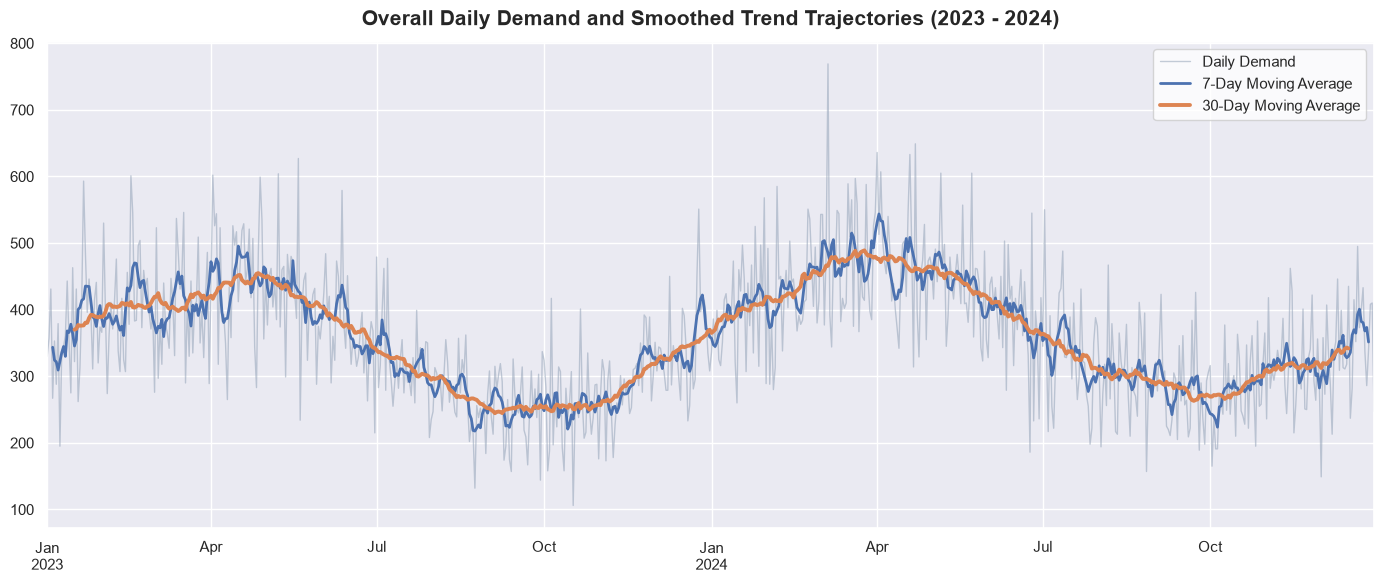

In [5]:
# Overall Daily Demand
daily_demand = data.groupby('date')['demand'].sum()

# Compute rolling moving averages for short-term and macro trends
trend_data = pd.DataFrame({'Daily Demand': daily_demand})
trend_data['7-Day MA'] = daily_demand.rolling(window=7, center=True).mean()
trend_data['30-Day MA'] = daily_demand.rolling(window=30, center=True).mean()

fig, ax = plt.subplots(figsize=(14, 6))

trend_data['Daily Demand'].plot(ax=ax, color='#94a3b8', alpha=0.55, linewidth=1.0, label='Daily Demand')
trend_data['7-Day MA'].plot(ax=ax, linewidth=2.0, label='7-Day Moving Average')
trend_data['30-Day MA'].plot(ax=ax, linewidth=2.8, label='30-Day Moving Average')

ax.set_title('Overall Daily Demand and Smoothed Trend Trajectories (2023 - 2024)', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('')
ax.set_ylabel('')
ax.legend(frameon=True, facecolor='white', loc='upper right')

plt.tight_layout()
save_figure(fig, 'overall_demand_trend')
plt.show()

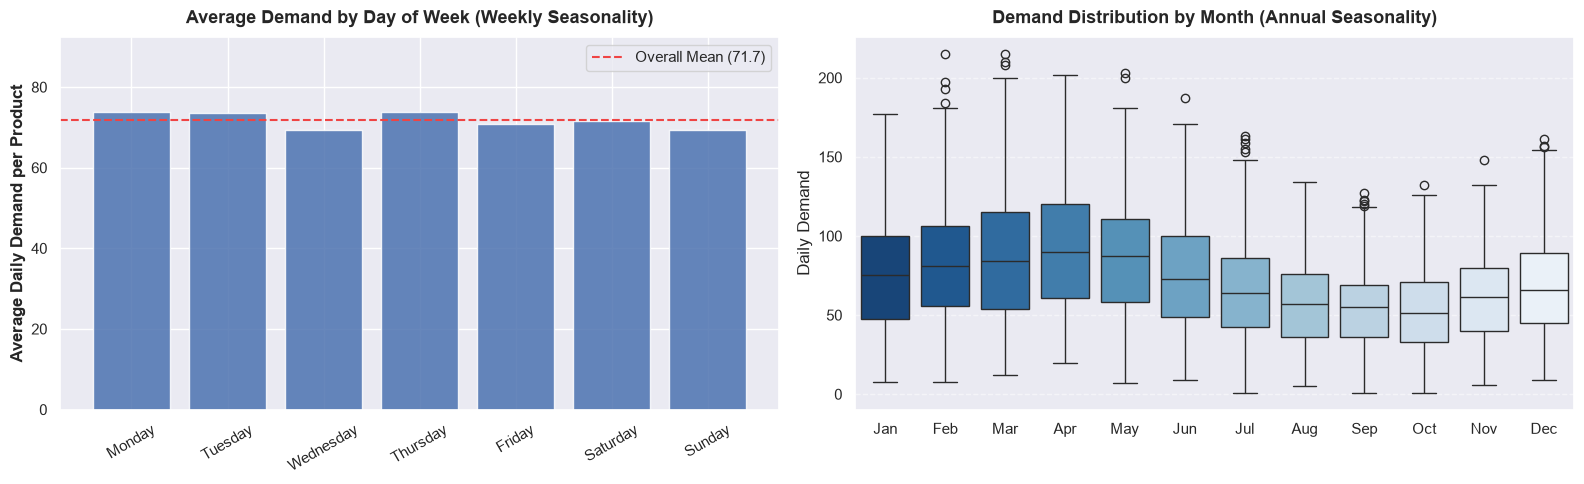

DOW Demand - Max: 73.93, Min: 69.31


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Day of Week Seasonality (using DAY_ORDER from utils)
dow_demand = data.groupby('day_name')['demand'].mean().reindex(DAY_ORDER)

axes[0].bar(dow_demand.index, dow_demand.values, alpha=0.85)
axes[0].axhline(dow_demand.mean(), color='#ef4444', linestyle='--', linewidth=1.5, label=f"Overall Mean ({dow_demand.mean():.1f})")
axes[0].set_title('Average Demand by Day of Week (Weekly Seasonality)', fontsize=13, fontweight='bold', pad=10)
axes[0].set_ylabel('Average Daily Demand per Product', fontweight='bold')
axes[0].set_ylim(0, dow_demand.max() * 1.25)
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend()

# Monthly Seasonality (using MONTH_ORDER from utils)
sns.boxplot(data=data, x='month_name', y='demand', hue='month_name', legend=False, order=MONTH_ORDER, palette='Blues_r', ax=axes[1])
axes[1].set_title('Demand Distribution by Month (Annual Seasonality)', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('')
axes[1].set_ylabel('Daily Demand')
axes[1].grid(True, linestyle='--', alpha=0.5, axis='y')

plt.tight_layout()
save_figure(fig, 'seasonality_dow_month')
plt.show()

print(f"DOW Demand - Max: {dow_demand.max():.2f}, Min: {dow_demand.min():.2f}")

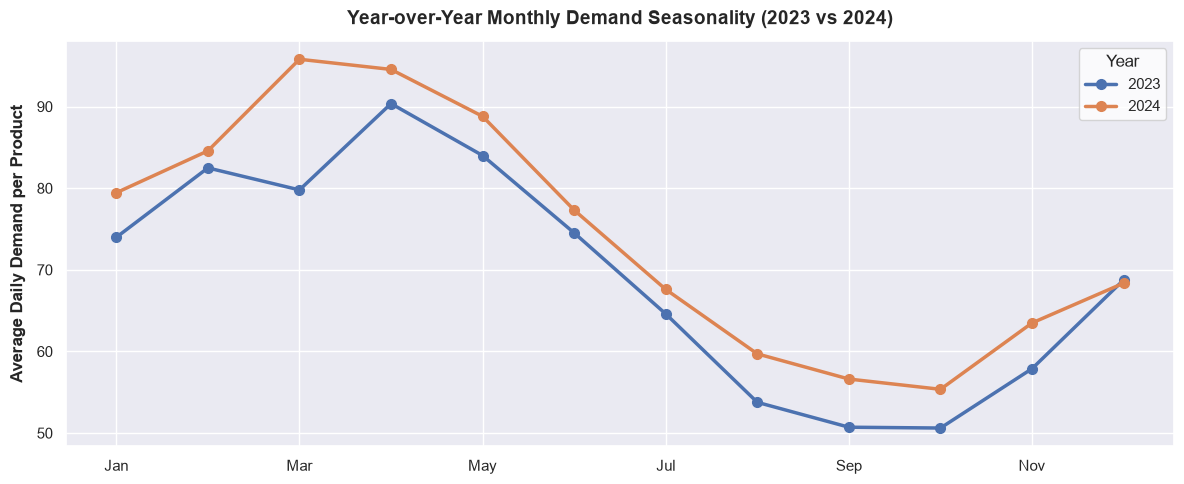

In [7]:
# Year-over-Year (YoY) Monthly Demand Seasonality (using MONTH_ORDER from utils)
yoy_pivot = data.pivot_table(index='month_name', columns='year', values='demand', aggfunc='mean').reindex(MONTH_ORDER)

fig, ax = plt.subplots(figsize=(12, 5))
yoy_pivot.plot(ax=ax, marker='o', linewidth=2.5, markersize=7)

ax.set_title('Year-over-Year Monthly Demand Seasonality (2023 vs 2024)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('')
ax.set_ylabel('Average Daily Demand per Product', fontweight='bold', labelpad=8)
ax.legend(title='Year', frameon=True, facecolor='white')

plt.tight_layout()
save_figure(fig, 'yoy_monthly_demand')
plt.show()

**Observations**:
- Daily demand is volatile, but a clear annual cycle emerges: demand peaks in April (~92) and bottoms out in September-October (~53), so the peak is roughly 75% above the trough.
- There is no meaningful weekly pattern: day-of-week averages range only from 69 to 74.
- The annual curve repeats in 2023 and 2024. 2024 is about 7% higher on average, but the gap is uneven across months, and two years are not enough to tell a trend from a one-off shift.

## 2. Product Comparison

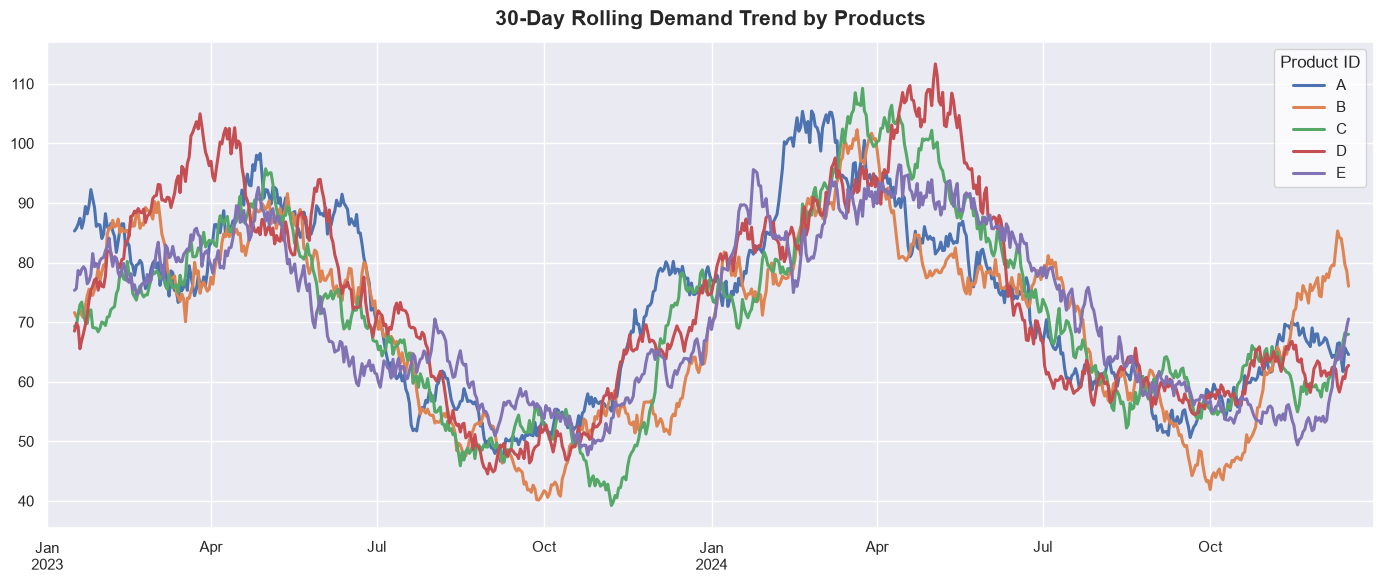

In [8]:
# Product-Level Demand Trends
product_pivot = data.pivot(index='date', columns='product_id', values='demand')
product_trend = product_pivot.rolling(window=30, center=True).mean()

fig, ax = plt.subplots(figsize=(14, 6))

product_trend.plot(ax=ax, linewidth=2.2)
ax.set_title('30-Day Rolling Demand Trend by Products', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('')
ax.set_ylabel('')
ax.legend(title='Product ID', frameon=True, facecolor='white', loc='upper right')

plt.tight_layout()
save_figure(fig, 'product_demand_trend')
plt.show()

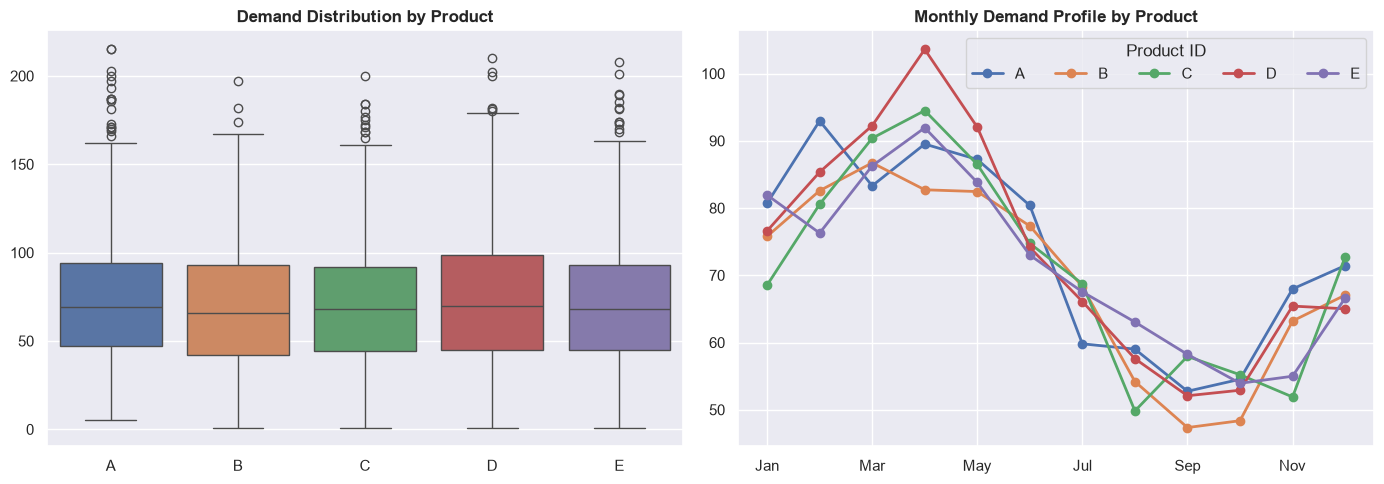

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=data, x='product_id', y='demand', hue='product_id', legend=False, ax=axes[0])
axes[0].set_title('Demand Distribution by Product', fontweight='bold')
axes[0].set_ylabel('')
axes[0].set_xlabel('')

# Monthly profile using MONTH_ORDER from utils
monthly = data.pivot_table(index='month_name', columns='product_id', values='demand', aggfunc='mean').reindex(MONTH_ORDER)
monthly.plot(ax=axes[1], marker='o', linewidth=2)
axes[1].set_title('Monthly Demand Profile by Product', fontweight='bold')
axes[1].set_xlabel('')
axes[1].legend(title='Product ID', ncol=5, loc='upper right')

plt.tight_layout()
save_figure(fig, 'product_profiles')
plt.show()

**Observations**: The five products have similar levels (means approx 70-74), spreads and seasonal shapes, and their 30-day averages move together. Small differences, such as product A peaking earlier, are probably noise given limited data per product-month.

## 3. What Drives Demand?

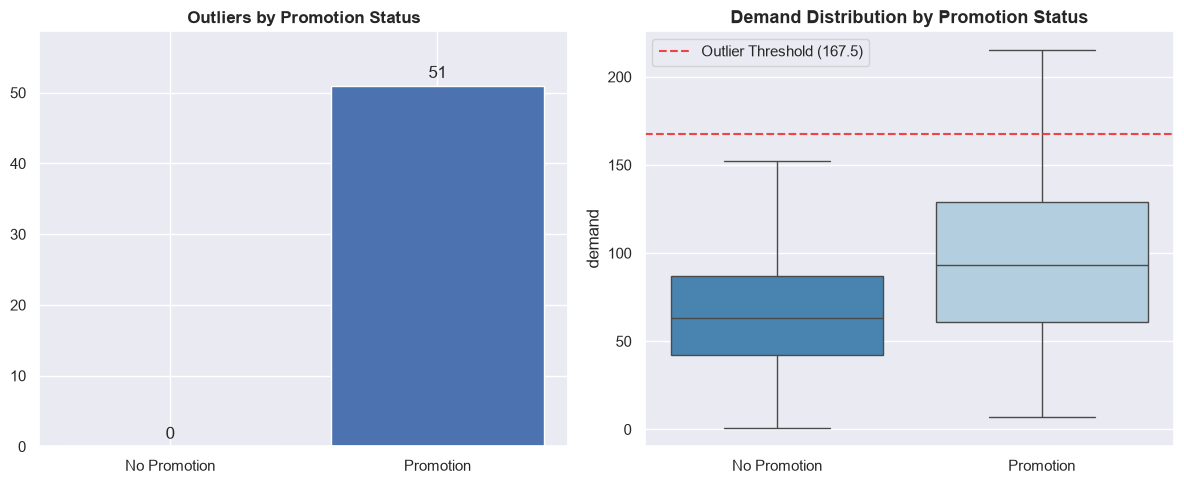

In [10]:
# Outlier detection via IQR
Q1 = data['demand'].quantile(0.25)
Q3 = data['demand'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
data['is_outlier'] = data['demand'] > upper_bound

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Outliers by Promotion Status
outlier_counts = pd.crosstab(data['promotion'], data['is_outlier'])[True].rename({0: 'No Promotion', 1: 'Promotion'})
bars = axes[0].bar(outlier_counts.index, outlier_counts.values)
axes[0].bar_label(bars, fmt='%d', padding=3)
axes[0].set_ylim(0, max(outlier_counts.values) * 1.15)
axes[0].set_title('Outliers by Promotion Status', fontweight='bold')

# Boxplot by Promotion Status
sns.boxplot(data=data, x='promotion', y='demand', hue='promotion', legend=False, showfliers=False, palette='Blues_r', ax=axes[1])
axes[1].axhline(upper_bound, color='#ef4444', linestyle='--', label=f"Outlier Threshold ({upper_bound:.1f})")
axes[1].set_title('Demand Distribution by Promotion Status', fontsize=13, fontweight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No Promotion', 'Promotion'])
axes[1].set_xlabel('')
axes[1].legend()

plt.tight_layout()
save_figure(fig, 'promotion_outliers')
plt.show()

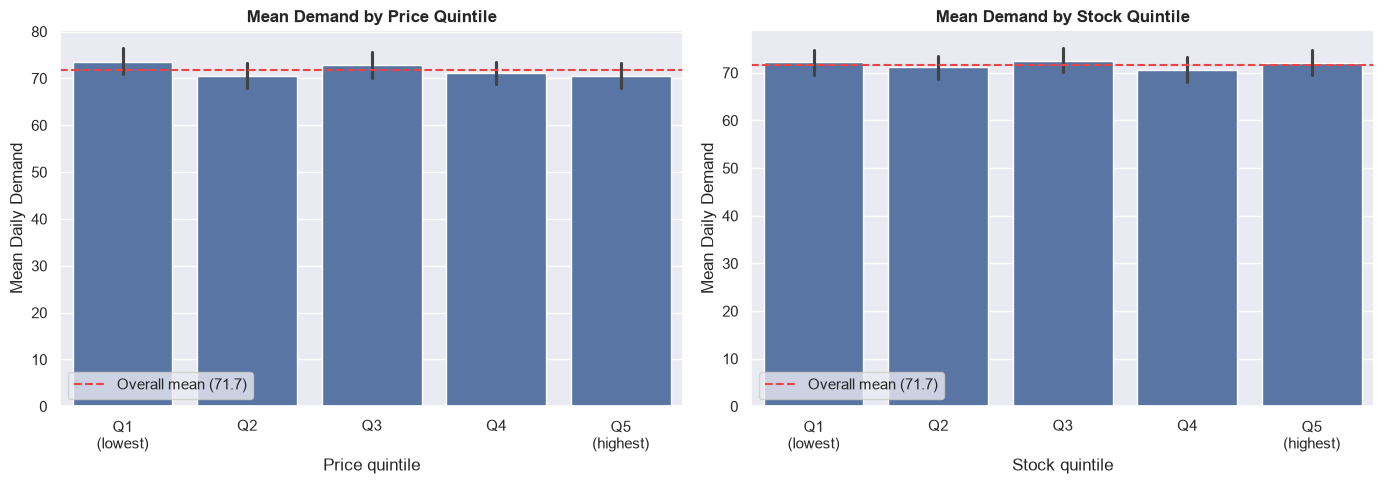

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
overall = data['demand'].mean()

for ax, col in zip(axes, ['price', 'stock']):
    q = pd.qcut(data[col], 5, labels=['Q1\n(lowest)', 'Q2', 'Q3', 'Q4', 'Q5\n(highest)'])
    sns.barplot(x=q, y=data['demand'], color='#4c72b0', ax=ax)   # error bars = 95% CI
    ax.axhline(overall, color='#ef4444', linestyle='--', label=f'Overall mean ({overall:.1f})')
    ax.set_title(f'Mean Demand by {col.title()} Quintile', fontweight='bold')
    ax.set_xlabel(f'{col.title()} quintile')
    ax.set_ylabel('Mean Daily Demand')
    ax.legend()

plt.tight_layout()
save_figure(fig, 'price_stock_quintiles')
plt.show()

**Price sensitivity.** The quintile bars above are a visual check. To quantify it, regress the log of demand (relative to its month x promotion expectation) on log price: the slope is a price elasticity, and its confidence interval says which effect sizes the data can rule out.

In [12]:
expected = data.groupby(['month', 'promotion'])['demand'].transform('mean')
rel_demand = data['demand'] / expected

def elasticity(frame):
    r = stats.linregress(np.log(frame['price']), np.log(rel_demand.loc[frame.index]))
    return pd.Series({'elasticity': r.slope, 'CI low': r.slope - 1.96 * r.stderr, 'CI high': r.slope + 1.96 * r.stderr,
                      'p-value': r.pvalue, 'rows': len(frame)})

rows = {'All rows': elasticity(data),
        'Promotion days': elasticity(data[data['promotion'] == 1]),
        'No-promotion days': elasticity(data[data['promotion'] == 0])}
for pid, g in data.groupby('product_id'):
    rows[f'Product {pid}'] = elasticity(g)
pd.DataFrame(rows).T.round(3)

,elasticity,CI low,CI high,p-value,rows
All rows,-0.010,-0.034,0.015,0.431,3650.0
Promotion days,-0.017,-0.064,0.031,0.493,727.0
No-promotion days,-0.008,-0.036,0.020,0.568,2923.0
Product A,0.031,-0.018,0.080,0.221,730.0
Product B,0.004,-0.051,0.058,0.900,730.0
Product C,-0.049,-0.105,0.006,0.081,730.0
Product D,-0.063,-0.120,-0.006,0.031,730.0
Product E,0.029,-0.027,0.084,0.313,730.0


**Observations**:
- Promotion lifts mean demand from ~65 to ~97 (+48%) and makes it more volatile (std approx 44 vs 31). All 51 outliers fall on promotion days, so they reflect a promotion response rather than data errors and are kept.
- Mean demand is flat across price and stock quintiles (approx 71-74) with overlapping confidence intervals, so neither shows a visible effect.
- The log-log regression puts the price elasticity at -0.01 (95% CI -0.03 to +0.015), so any elasticity stronger than about -0.03 is ruled out. Per product the estimates run from +0.03 to -0.06 and one of the eight estimates is nominally significant (product D, p = 0.03), which is about what chance produces across eight tests. There is no price effect to model in this dataset (see the caveat in Section 0.1).


## 4. What Is Left After Month and Promotion?

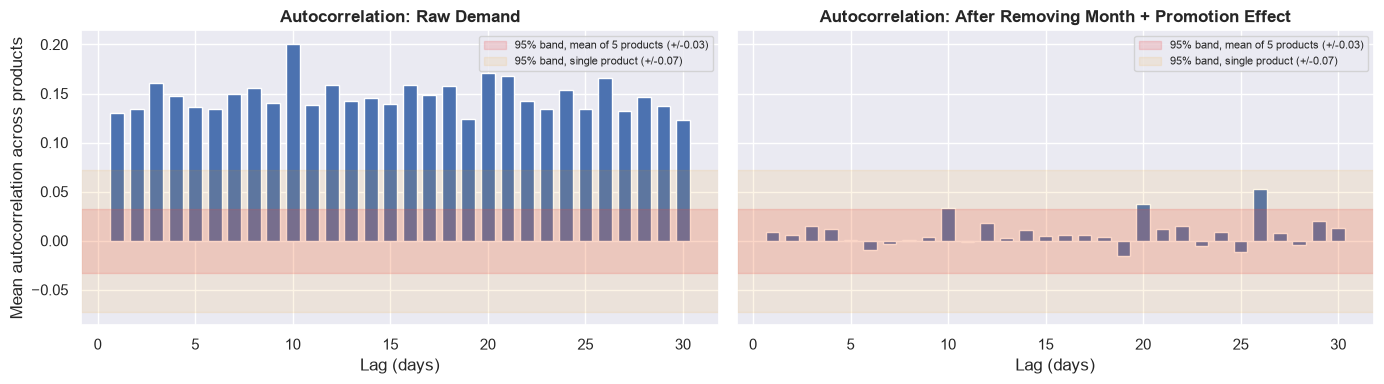

In [13]:
# Remove month and promotion effects to analyze residual variance
data['adj_demand'] = data['demand'] - data.groupby(['month', 'promotion'])['demand'].transform('mean')

max_lag = 30
n = data.groupby('product_id').size().iloc[0]
n_prod = data['product_id'].nunique()
band_one = 1.96 / np.sqrt(n)                # approx. 95% noise band for ONE product's autocorrelation
band_mean = band_one / np.sqrt(n_prod)      # ... for the average of n_prod independent products (narrower)
lags = np.arange(1, max_lag + 1)

def acf_by_product(col):
    return pd.DataFrame({pid: [g[col].autocorr(l) for l in lags] for pid, g in data.groupby('product_id')}, index=lags)

acf_raw, acf_adj = acf_by_product('demand'), acf_by_product('adj_demand')

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (title, acf) in zip(axes, [('Raw Demand', acf_raw), ('After Removing Month + Promotion Effect', acf_adj)]):
    ax.bar(lags, acf.mean(axis=1), width=0.7)
    ax.axhspan(-band_mean, band_mean, color='#ef4444', alpha=0.18, label=f'95% band, mean of {n_prod} products (+/-{band_mean:.2f})')
    ax.axhspan(-band_one, band_one, color='#f59e0b', alpha=0.10, label=f'95% band, single product (+/-{band_one:.2f})')
    ax.set_title(f'Autocorrelation: {title}', fontweight='bold')
    ax.set_xlabel('Lag (days)')
    ax.legend(fontsize=8)
axes[0].set_ylabel('Mean autocorrelation across products')

plt.tight_layout()
save_figure(fig, 'autocorrelation')
plt.show()

In [14]:
n_out = int((acf_adj.abs() > band_one).sum().sum())
n_out_mean = int((acf_adj.mean(axis=1).abs() > band_mean).sum())
print(f"After removing month + promotion: {n_out} of {acf_adj.size} product-lag values lie outside the single-product band "
      f"(about {0.05 * acf_adj.size:.1f} expected by chance); the product-average lies outside its own band at {n_out_mean} of {max_lag} lags.")
print(f"Largest single value: {acf_adj.abs().stack().idxmax()} = {acf_adj.stack()[acf_adj.abs().stack().idxmax()]:+.2f}")

show_lags = [1, 7, 30]
rows = []
for pid in acf_raw.columns:
    for name, acf in [('raw', acf_raw), ('adjusted', acf_adj)]:
        rows.append({'product': pid, 'series': name, **{f'lag{l}': acf.loc[l, pid] for l in show_lags}})
pd.DataFrame(rows).round(2)

After removing month + promotion: 11 of 150 product-lag values lie outside the single-product band (about 7.5 expected by chance); the product-average lies outside its own band at 3 of 30 lags.
Largest single value: (np.int64(30), 'C') = +0.13


,product,series,lag1,lag7,lag30
0,A,raw,0.10,0.15,0.10
1,A,adjusted,-0.03,0.01,0.00
2,B,raw,0.17,0.19,0.14
3,B,adjusted,0.05,0.06,0.02
4,C,raw,0.14,0.18,0.21
5,C,adjusted,0.00,-0.01,0.13
6,D,raw,0.16,0.11,0.12
7,D,adjusted,0.04,-0.05,-0.01
8,E,raw,0.08,0.12,0.05
9,E,adjusted,-0.01,-0.02,-0.08


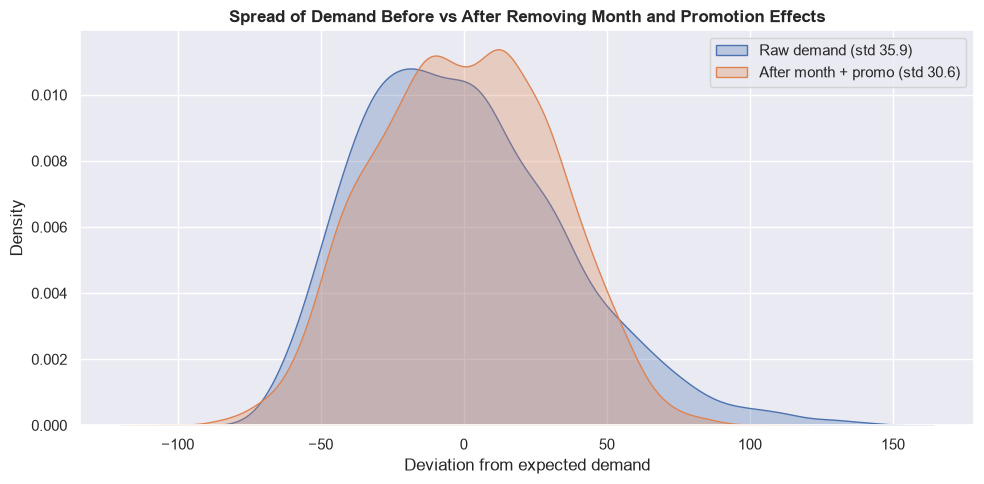

In [15]:
raw_dev = data['demand'] - data['demand'].mean()

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(raw_dev, ax=ax, fill=True, alpha=0.3, label=f'Raw demand (std {raw_dev.std():.1f})')
sns.kdeplot(data['adj_demand'], ax=ax, fill=True, alpha=0.3, label=f"After month + promo (std {data['adj_demand'].std():.1f})")
ax.set_title('Spread of Demand Before vs After Removing Month and Promotion Effects', fontweight='bold')
ax.set_xlabel('Deviation from expected demand')
ax.legend()

plt.tight_layout()
save_figure(fig, 'demand_spread_reduction')
plt.show()

In [16]:
cv_raw = data['demand'].std() / data['demand'].mean()

grp = data.groupby(['month', 'promotion'])['demand'].agg(['mean', 'std'])
cv_grp = grp['std'] / grp['mean']

print(f"Raw CV: {cv_raw:.2f}")
print(f"CV within (month, promo) groups: mean {cv_grp.mean():.2f}, range {cv_grp.min():.2f}-{cv_grp.max():.2f}")
print(f"Std raw: {data['demand'].std():.1f} -> std after removing month+promo: {data['adj_demand'].std():.1f}")

Raw CV: 0.50
CV within (month, promo) groups: mean 0.41, range 0.36-0.46
Std raw: 35.9 -> std after removing month+promo: 30.6


**Observations**:
- Raw demand is positively autocorrelated at all lags (product average 0.12-0.20), largely because month-level seasonality persists over weeks.
- Once month and promotion effects are removed, the product-average autocorrelation is within +/-0.05 at every lag (largest +0.05 at lag 26). Against the correct band for an average of five products (+/-0.03), three lags (10, 20 and 26) are marginally outside, close to the 1.5 expected by chance. For single products, 11 of 150 values exceed +/-0.07 (7.5 expected), the largest being product C at lag 30 (+0.13).
- These correlations are too small to matter (an autocorrelation of 0.05 explains 0.25% of the variance), so there is no evidence that past demand adds usable information beyond month and promotion. The claim is "nothing material", not "exactly zero".
- Month and promotion explain only about 27% of the variance (std falls from ~36 to ~31), so substantial day-to-day uncertainty remains.


<a id="section-5"></a>
## 5. Key Insights and Next Steps

| Finding | Decision for modelling |
| :--- | :--- |
| Strong annual cycle, no weekly effect | Month-of-year or Fourier terms; no day-of-week feature |
| 2024 ≈ 7% above 2023 (two years only) | Test a trend/year term via CV; avoid blind extrapolation |
| Promotion: +48% and higher variance | Promotion flag as a key feature; keep promo outliers |
| Five similar products | One pooled model with product_id; compare against per-product models by CV |
| Price, stock show no effect (elasticity CI -0.03 to +0.015) | Drop them; confirm with a CV ablation |
| No material residual autocorrelation | Skip lag/AR features (not cross-validated: at a 60-day horizon recent lags are mostly unavailable anyway) |
| ~73% of variance remains | Quantile or distributional forecasts; size safety stock from forecast error |
| Data looks simulated (uniform price/stock, 1:1 category) | State the limits of every finding; re-test on real data before generalising |

---
### Next Steps
Proceed to model implementation and evaluation in **[notebooks/forecasting.ipynb](forecasting.ipynb)**.